# Hotel Booking Cancellation Prediction
## CDS 4003 – Data Science for Business Application

### Stage 3: Data Understanding and Cleaning

This notebook explores the hotel booking dataset,
identifies data quality issues, and prepares the data
for machine learning.

In [14]:
#Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
#loading dataset

df = pd.read_csv("hotel_bookings.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [16]:
#Exploring data

# Check column names and data types
df.info()

# Display summary statistics
display(df.describe(include="all"))

# Check missing values
display(df.isnull().sum())

# Check duplicate rows
print("Duplicates:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
count,119390,119390.000000,119390.000000,119390.000000,119390,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,...,119390,103050.000000,6797.000000,119390.000000,119390,119390.000000,119390.000000,119390.000000,119390,119390
unique,2,NaN,NaN,NaN,12,NaN,NaN,NaN,NaN,NaN,...,3,NaN,NaN,NaN,4,NaN,NaN,NaN,3,926
top,City Hotel,NaN,NaN,NaN,August,NaN,NaN,NaN,NaN,NaN,...,No Deposit,NaN,NaN,NaN,Transient,NaN,NaN,NaN,Check-Out,2015-10-21
freq,79330,NaN,NaN,NaN,13877,NaN,NaN,NaN,NaN,NaN,...,104641,NaN,NaN,NaN,89613,NaN,NaN,NaN,75166,1461
mean,NaN,0.370416,104.011416,2016.156554,NaN,27.165173,15.798241,0.927599,2.500302,1.856403,...,NaN,86.693382,189.266735,2.321149,NaN,101.831122,0.062518,0.571363,NaN,NaN
std,NaN,0.482918,106.863097,0.707476,NaN,13.605138,8.780829,0.998613,1.908286,0.579261,...,NaN,110.774548,131.655015,17.594721,NaN,50.535790,0.245291,0.792798,NaN,NaN
min,NaN,0.000000,0.000000,2015.000000,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,...,NaN,1.000000,6.000000,0.000000,NaN,-6.380000,0.000000,0.000000,NaN,NaN
25%,NaN,0.000000,18.000000,2016.000000,NaN,16.000000,8.000000,0.000000,1.000000,2.000000,...,NaN,9.000000,62.000000,0.000000,NaN,69.290000,0.000000,0.000000,NaN,NaN
50%,NaN,0.000000,69.000000,2016.000000,NaN,28.000000,16.000000,1.000000,2.000000,2.000000,...,NaN,14.000000,179.000000,0.000000,NaN,94.575000,0.000000,0.000000,NaN,NaN
75%,NaN,1.000000,160.000000,2017.000000,NaN,38.000000,23.000000,2.000000,3.000000,2.000000,...,NaN,229.000000,270.000000,0.000000,NaN,126.000000,0.000000,1.000000,NaN,NaN


hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

Duplicates: 31994


## 6. Data Cleaning

### 6.1 Handling Missing Values

The dataset contains missing values in children, country,
agent, and company. We will handle these values based on
what each column represents.

In [17]:
#Data Cleaning

# Create a copy to keep the original data unchanged
df_clean = df.copy()

# Fill missing children values with 0
df_clean["children"] = df_clean["children"].fillna(0)

# Fill missing country values with "Unknown"
df_clean["country"] = df_clean["country"].fillna("Unknown")

# Fill missing agent and company IDs with 0
# 0 represents missing or unrecorded IDs
df_clean["agent"] = df_clean["agent"].fillna(0)
df_clean["company"] = df_clean["company"].fillna(0)

# Check missing values after cleaning
print("Missing Values After Cleaning:")
print(df_clean.isnull().sum())

print("Total Missing Values:", df_clean.isnull().sum().sum())


Missing Values After Cleaning:
hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                    

### 6.2 Handling Duplicate Rows

We will check for duplicate rows in the dataset.
Since different hotel bookings can have identical
details, we will investigate them before deciding
whether to remove them.

In [18]:
# Count duplicate rows
duplicates = df_clean.duplicated().sum()

print("Duplicate Rows:", duplicates)

# Show examples of duplicate rows
display(df_clean[df_clean.duplicated(keep=False)].head(10))

# Check dataset size
print("Total Rows:", len(df_clean))


Duplicate Rows: 31994


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,0.0,0,Transient,98.00,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,0.0,0,Transient,98.00,0,1,Check-Out,2015-07-03
21,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,0.0,0,Transient,84.67,0,1,Check-Out,2015-07-07
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,0.0,0,Transient,84.67,0,1,Check-Out,2015-07-07
39,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,0.0,0,Transient,137.00,0,1,Check-Out,2015-07-07
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,0.0,0,Transient,137.00,0,1,Check-Out,2015-07-07
132,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,No Deposit,240.0,0.0,0,Transient,97.00,0,0,Canceled,2015-07-01
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,No Deposit,240.0,0.0,0,Transient,97.00,0,0,Canceled,2015-07-01
198,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,No Deposit,240.0,0.0,0,Transient,109.80,0,3,Check-Out,2015-07-08
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,No Deposit,240.0,0.0,0,Transient,109.80,0,3,Check-Out,2015-07-08


Total Rows: 119390


### 6.3 Checking Invalid Values and Outliers

We will check for invalid and unusual values in the dataset, such as bookings with zero guests, negative hotel prices, and unusually high lead times or daily rates.

These checks will help us identify data quality issues before deciding how to clean them.

In [19]:
# Check bookings with zero guests
zero_guests = df_clean[
    (df_clean["adults"] +
     df_clean["children"] +
     df_clean["babies"]) == 0
]

print("Bookings with zero guests:", len(zero_guests))

# Check negative hotel prices
print("Negative prices:", (df_clean["adr"] < 0).sum())

# Check unusual lead times
print("Maximum lead time:", df_clean["lead_time"].max())

# Check maximum daily rate
print("Maximum daily rate:", df_clean["adr"].max())

Bookings with zero guests: 180
Negative prices: 1
Maximum lead time: 737
Maximum daily rate: 5400.0


### 6.4 Handling Invalid Values

We will remove bookings with zero guests and negative hotel prices because these values are not valid for normal hotel reservations.

We will keep unusually high lead times and daily rates for further investigation instead of removing them automatically.

In [20]:
# Store the number of rows before cleaning
rows_before = len(df_clean)

# Remove bookings with zero guests
df_clean = df_clean[
    (df_clean["adults"] +
     df_clean["children"] +
     df_clean["babies"]) > 0
].copy()

# Remove bookings with negative prices
df_clean = df_clean[df_clean["adr"] >= 0].copy()

# Compare before and after
print("Rows Before:", rows_before)
print("Rows After:", len(df_clean))
print("Rows Removed:", rows_before - len(df_clean))

# Verify cleaning
print("Zero Guest Bookings:",
      ((df_clean["adults"] +
        df_clean["children"] +
        df_clean["babies"]) == 0).sum())

print("Negative Prices:",
      (df_clean["adr"] < 0).sum())


Rows Before: 119390
Rows After: 119209
Rows Removed: 181
Zero Guest Bookings: 0
Negative Prices: 0


### 6.5 Checking Inconsistent Values

We will check the categorical columns for inconsistent values, spelling differences, and unexpected categories.

This will help us decide whether any values need to be standardized.

In [21]:
# Check unique values in important categorical columns
columns_to_check = [
    "hotel",
    "meal",
    "market_segment",
    "distribution_channel",
    "deposit_type",
    "customer_type",
    "reservation_status"
]

for col in columns_to_check:
    print("\nColumn:", col)
    print(df_clean[col].value_counts(dropna=False))



Column: hotel
hotel
City Hotel      79163
Resort Hotel    40046
Name: count, dtype: int64

Column: meal
meal
BB           92235
HB           14458
SC           10549
Undefined     1169
FB             798
Name: count, dtype: int64

Column: market_segment
market_segment
Online TA        56408
Offline TA/TO    24182
Groups           19790
Direct           12582
Corporate         5282
Complementary      728
Aviation           235
Undefined            2
Name: count, dtype: int64

Column: distribution_channel
distribution_channel
TA/TO        97750
Direct       14610
Corporate     6651
GDS            193
Undefined        5
Name: count, dtype: int64

Column: deposit_type
deposit_type
No Deposit    104460
Non Refund     14587
Refundable       162
Name: count, dtype: int64

Column: customer_type
customer_type
Transient          89476
Transient-Party    25087
Contract            4072
Group                574
Name: count, dtype: int64

Column: reservation_status
reservation_status
Check-Out    7

### 6.6 Data Types and Date Transformation

We will convert the arrival date columns into one date column and check that the data types are correct.

This will make the dataset easier to analyze and prepare for machine learning.

In [22]:
# Create a complete arrival date
df_clean["arrival_date"] = pd.to_datetime(
    df_clean["arrival_date_year"].astype(str) + "-" +
    df_clean["arrival_date_month"] + "-" +
    df_clean["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d",
    errors="coerce"
)

# Check the new date column
print("Arrival Date Type:", df_clean["arrival_date"].dtype)

# Check for invalid dates
print("Invalid Dates:", df_clean["arrival_date"].isnull().sum())

# Display the first five dates
display(df_clean["arrival_date"].head())


Arrival Date Type: datetime64[us]
Invalid Dates: 0


0   2015-07-01
1   2015-07-01
2   2015-07-01
3   2015-07-01
4   2015-07-01
Name: arrival_date, dtype: datetime64[us]

### 6.7 Before and After Data Cleaning

We will compare the original dataset with the cleaned
dataset to show the improvements in data quality.

We will also identify any remaining concerns that
need further investigation.

In [23]:
# Function to count invalid bookings
def count_invalid(data):
    zero_guests = (
        data["adults"] +
        data["children"].fillna(0) +
        data["babies"]
    ) == 0

    return zero_guests.sum()

# Create before-and-after summary
summary = pd.DataFrame({
    "Quality Check": [
        "Total Rows",
        "Missing Values",
        "Duplicate Rows",
        "Zero Guest Bookings",
        "Negative Prices"
    ],
    "Before Cleaning": [
        len(df),
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        count_invalid(df),
        (df["adr"] < 0).sum()
    ],
    "After Cleaning": [
        len(df_clean),
        df_clean.isnull().sum().sum(),
        df_clean.duplicated().sum(),
        count_invalid(df_clean),
        (df_clean["adr"] < 0).sum()
    ]
})

display(summary)


,Quality Check,Before Cleaning,After Cleaning
0,Total Rows,119390,119209
1,Missing Values,129425,0
2,Duplicate Rows,31994,31980
3,Zero Guest Bookings,180,0
4,Negative Prices,1,0


### 6.8 Investigating Outliers

We will use the Interquartile Range (IQR) method to identify
unusually high or low values in hotel prices and booking
lead times.

We will investigate these outliers before deciding whether
to remove them.

Column: adr
Lower Bound: -15.25
Upper Bound: 210.75
Number of Outliers: 3864

Column: lead_time
Lower Bound: -196.5
Upper Bound: 375.5
Number of Outliers: 2981



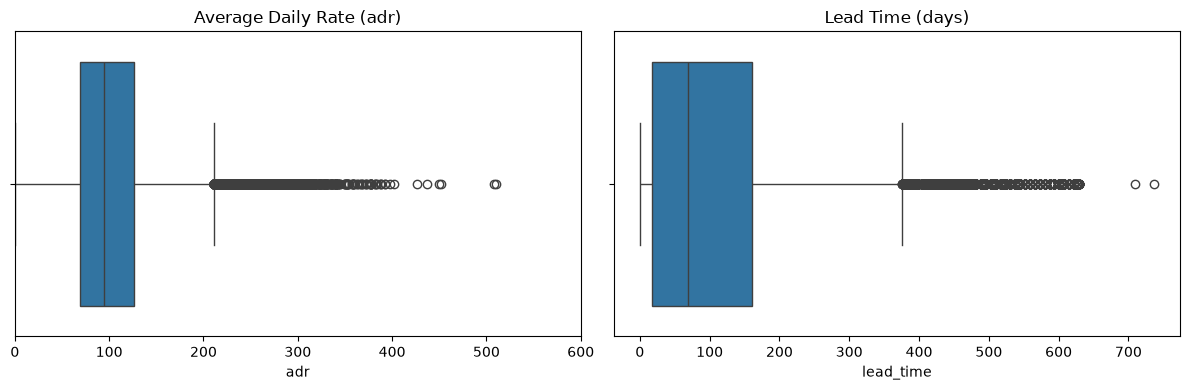

In [24]:
# Check outliers using the IQR method
for col in ["adr", "lead_time"]:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ]

    print("Column:", col)
    print("Lower Bound:", lower)
    print("Upper Bound:", upper)
    print("Number of Outliers:", len(outliers))
    print()

# Visualise outliers in adr and lead_time using boxplots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x=df_clean["adr"], ax=axes[0])
axes[0].set_title("Average Daily Rate (adr)")

sns.boxplot(x=df_clean["lead_time"], ax=axes[1])
axes[1].set_title("Lead Time (days)")
axes[0].set_xlim(0, 600)  # zoom in; the 5,400 value is outside this range
plt.tight_layout()
plt.show()


### 6.9 Final Cleaning Decisions

We handled missing values and removed bookings with invalid
guest counts or negative prices.

We kept duplicate rows because the dataset does not have
a unique booking ID, so identical rows may represent
different reservations.

We also kept the statistical outliers because unusually
high prices and lead times may be valid.

These remaining issues will be considered during
machine learning.

In [25]:
# Save the cleaned dataset
df_clean.to_csv("hotel_bookings_cleaned.csv", index=False)

# Final verification
print("Cleaned Dataset Shape:", df_clean.shape)
print("Remaining Missing Values:", df_clean.isnull().sum().sum())
print("Remaining Duplicate Rows:", df_clean.duplicated().sum())

print("Cleaned dataset saved successfully!")


Cleaned Dataset Shape: (119209, 33)
Remaining Missing Values: 0
Remaining Duplicate Rows: 31980
Cleaned dataset saved successfully!
